# Project 12: Understanding Convolution and Pooling

**Course:** Deep Learning  
**Objective:** To understand how convolution filters extract image features and how pooling reduces spatial dimensions while preserving useful information.

## Understanding
Convolution applies a small matrix called a *kernel* or *filter* across an image. Different kernels can highlight edges, sharpen details, or detect other patterns. Pooling summarizes small regions of a feature map. Max pooling keeps the maximum value in each region, while average pooling calculates the mean.

**Libraries:** NumPy, Matplotlib, Pillow, and SciPy.

## Task 1: Load a sample image
I use a sample image created with Python so the notebook works without downloading an image from the internet.

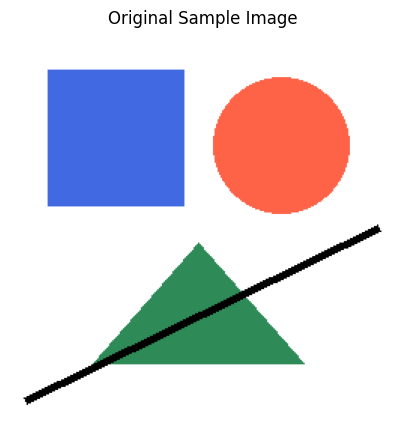

Image shape (height, width, channels): (256, 256, 3)
Grayscale image shape: (256, 256)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scipy.signal import convolve2d

# Create a simple RGB sample image with shapes and edges
width, height = 256, 256
sample = Image.new("RGB", (width, height), "white")
draw = ImageDraw.Draw(sample)
draw.rectangle((25, 25, 115, 115), fill="royalblue")
draw.ellipse((135, 30, 225, 120), fill="tomato")
draw.polygon([(55, 220), (125, 140), (195, 220)], fill="seagreen")
draw.line((10, 245, 245, 130), fill="black", width=5)

image = np.asarray(sample)
gray = np.asarray(sample.convert("L"), dtype=float)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Original Sample Image")
plt.axis("off")
plt.show()

print("Image shape (height, width, channels):", image.shape)
print("Grayscale image shape:", gray.shape)

## Task 2: Apply convolution filters and pooling

I convert the image to grayscale and apply two convolution kernels:
- **Edge detection:** highlights sudden intensity changes and object boundaries.
- **Sharpening:** emphasizes details and edges.

I then apply max pooling and average pooling using non-overlapping 2 × 2 regions.

In [2]:
# Convolution kernels
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=float)

sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=float)

# 'same' keeps the output dimensions the same as the input
edge_map = convolve2d(gray, edge_kernel, mode="same", boundary="symm")
sharpened = convolve2d(gray, sharpen_kernel, mode="same", boundary="symm")

def pool2x2(array, mode="max"):
    # Crop to even dimensions before reshaping into 2x2 regions
    h = (array.shape[0] // 2) * 2
    w = (array.shape[1] // 2) * 2
    cropped = array[:h, :w]
    blocks = cropped.reshape(h // 2, 2, w // 2, 2)
    if mode == "max":
        return blocks.max(axis=(1, 3))
    if mode == "average":
        return blocks.mean(axis=(1, 3))
    raise ValueError("mode must be 'max' or 'average'")

max_pooled = pool2x2(edge_map, "max")
average_pooled = pool2x2(edge_map, "average")

print("Original grayscale shape:", gray.shape)
print("Edge feature map shape:", edge_map.shape)
print("Max pooled shape:", max_pooled.shape)
print("Average pooled shape:", average_pooled.shape)

Original grayscale shape: (256, 256)
Edge feature map shape: (256, 256)
Max pooled shape: (128, 128)
Average pooled shape: (128, 128)


## Task 3: Visualize and compare the results
The plots below compare the original image, convolution outputs, and pooling results. The color scale is used to make positive and negative filter responses visible.

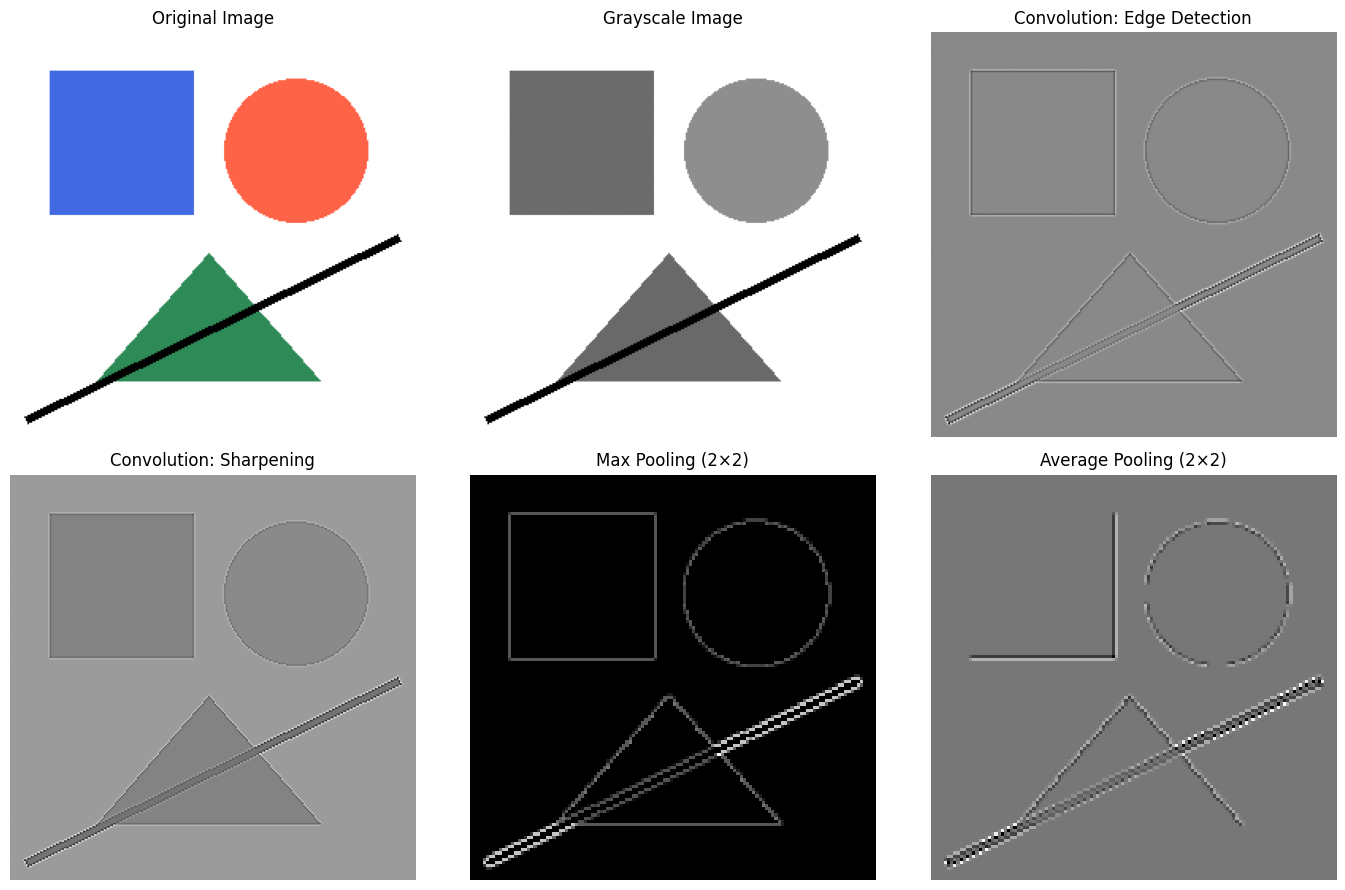

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(gray, cmap="gray")
axes[0, 1].set_title("Grayscale Image")
axes[0, 1].axis("off")

axes[0, 2].imshow(edge_map, cmap="gray")
axes[0, 2].set_title("Convolution: Edge Detection")
axes[0, 2].axis("off")

axes[1, 0].imshow(sharpened, cmap="gray")
axes[1, 0].set_title("Convolution: Sharpening")
axes[1, 0].axis("off")

axes[1, 1].imshow(max_pooled, cmap="gray")
axes[1, 1].set_title("Max Pooling (2×2)")
axes[1, 1].axis("off")

axes[1, 2].imshow(average_pooled, cmap="gray")
axes[1, 2].set_title("Average Pooling (2×2)")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

## Results and observations

1. The original image contains colored shapes, boundaries, and a diagonal line.
2. The edge-detection kernel produces strong responses around boundaries and sharp intensity changes.
3. The sharpening kernel emphasizes edges and details, making shapes appear more defined.
4. Max pooling keeps the largest value in each 2 × 2 region. It can preserve strong edge responses while reducing the feature map's height and width.
5. Average pooling calculates the mean of each 2 × 2 region. It smooths local variations and also reduces spatial dimensions.
6. In this example, the image is 256 × 256 pixels and the pooled maps are 128 × 128 pixels.

## Conclusion

This experiment demonstrates that convolution filters transform image pixels into feature maps that emphasize useful visual patterns. Pooling reduces spatial resolution and summarizes local regions, which can make later CNN processing more efficient. Convolution and pooling are important operations in many Convolutional Neural Networks (CNNs).

## New terminology

- **Kernel/filter:** A small matrix used to calculate local image responses.
- **Convolution:** Applying a kernel across an image to produce a feature map.
- **Feature map:** The output showing the response of a filter at different locations.
- **Edge detection:** Highlighting boundaries and rapid intensity changes.
- **Pooling:** Summarizing small image regions to reduce spatial dimensions.
- **Max pooling:** Keeping the maximum value from each region.
- **Average pooling:** Keeping the average value from each region.
- **Spatial dimensions:** The height and width of an image or feature map.